In [20]:
# ## Step 0. Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

In [21]:
# Make results repeatable: same seed -> same split and same model.
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [23]:
# ## Step 1. Load the small tables
patients = pd.read_csv("PATIENTS.csv",
    usecols=["SUBJECT_ID", "GENDER", "DOB"],
    parse_dates=["DOB"],
)
 
admissions = pd.read_csv("ADMISSIONS.csv",
    usecols=["HADM_ID", "ADMISSION_TYPE"],
)
 
icustays = pd.read_csv("ICUSTAYS.csv",
    usecols=["SUBJECT_ID", "HADM_ID", "ICUSTAY_ID", "INTIME", "LOS"],
    parse_dates=["INTIME"],
)
 
print("patients:", patients.shape)
print("admissions:", admissions.shape)
print("icustays:", icustays.shape)

patients: (46520, 3)
admissions: (58976, 2)
icustays: (61532, 5)


In [25]:
# ## Step 2. Build the cohort (who is in our study?)
icustays = icustays.dropna(subset=["LOS"])
 
# Sort by time, then keep the first row for each patient.
icustays = (icustays.sort_values(["SUBJECT_ID", "INTIME"])
                    .drop_duplicates(subset="SUBJECT_ID", keep="first"))
 
# Join demographics and admission type onto each ICU stay.
cohort = (icustays
          .merge(patients, on="SUBJECT_ID", how="left")
          .merge(admissions, on="HADM_ID", how="left"))
 
# Age = year of ICU admission minus year of birth.
# (Subtracting full timestamps can overflow in MIMIC because dates are
#  shifted for privacy, so we use only the years.)
# MIMIC shifts the birth date of patients older than 89 so they appear
# ~300 years old. We cap age at 90 to handle that.
cohort["AGE"] = cohort["INTIME"].dt.year - cohort["DOB"].dt.year
cohort["AGE"] = cohort["AGE"].clip(upper=90)
 
# Keep adults only (age >= 18).
cohort = cohort[cohort["AGE"] >= 18].copy()

Cohort size: 38536
PROLONGED
0    0.645967
1    0.354033
Name: share, dtype: float64


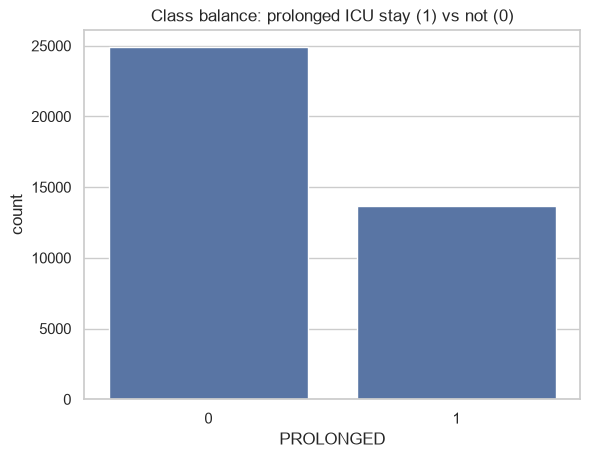

In [26]:
# ## Step 3. Create the label (what are we predicting?)

cohort["PROLONGED"] = (cohort["LOS"] >= 3).astype(int)
print("Cohort size:", len(cohort))
print(cohort["PROLONGED"].value_counts(normalize=True).rename("share"))
 
# Plot the class balance so we know whether accuracy alone would be misleading.
sns.countplot(data=cohort, x="PROLONGED")
plt.title("Class balance: prolonged ICU stay (1) vs not (0)")
plt.show()

In [27]:
# ## Step 4. Extract first-24-hour lab features from LABEVENTS

LAB_ITEMS = {
    50912: "creatinine",
    51006: "bun",
    50983: "sodium",
    50971: "potassium",
    50882: "bicarbonate",
    50931: "glucose",
    51222: "hemoglobin",
    51301: "wbc",
    51265: "platelets",
    50813: "lactate",
}

# A small lookup table of ICU admission times, used to define "first 24 hours".
stay_times = cohort[["HADM_ID", "INTIME"]]
valid_hadm = set(stay_times["HADM_ID"])

chunks = []
reader = pd.read_csv("LABEVENTS.csv",
    usecols=["HADM_ID", "ITEMID", "CHARTTIME", "VALUENUM"],
    parse_dates=["CHARTTIME"],
    chunksize=1_000_000,  # read one million rows at a time
)
for chunk in reader:
    # Keep only our lab tests, our cohort, and rows with a numeric value.
    chunk = chunk[chunk["ITEMID"].isin(LAB_ITEMS.keys())]
    chunk = chunk[chunk["HADM_ID"].isin(valid_hadm)]
    chunk = chunk.dropna(subset=["VALUENUM"])
    chunks.append(chunk)

labs = pd.concat(chunks, ignore_index=True)
print("Lab rows kept:", labs.shape)

labs = labs.merge(stay_times, on="HADM_ID", how="inner")
hours_since_icu = (labs["CHARTTIME"] - labs["INTIME"]).dt.total_seconds() / 3600
labs = labs[(hours_since_icu >= 0) & (hours_since_icu <= 24)]

# Give each ITEMID a readable name.
labs["LAB"] = labs["ITEMID"].map(LAB_ITEMS)

lab_features = (labs.groupby(["HADM_ID", "LAB"])["VALUENUM"].max()
                    .unstack("LAB")          # one column per lab
                    .reset_index())
print(lab_features.head())

Lab rows kept: (4195636, 4)
LAB   HADM_ID  bicarbonate   bun  creatinine  glucose  hemoglobin  lactate  \
0    100001.0         21.0  42.0         2.4    185.0        11.3      NaN   
1    100003.0         16.0  49.0         1.2    113.0        10.4      1.1   
2    100006.0         24.0  16.0         0.6    129.0        10.3      NaN   
3    100007.0         27.0  14.0         0.7    137.0        12.3      NaN   
4    100009.0         24.0  13.0         0.8    177.0        13.7      1.5   

LAB  platelets  potassium  sodium   wbc  
0        407.0        4.2   144.0  11.2  
1        162.0        5.0   133.0  14.2  
2        204.0        3.7   131.0  13.6  
3        259.0        4.7   140.0  12.3  
4        149.0        4.4   143.0  17.3  


In [28]:
# ## Step 5. Combine everything into one modeling table

df = cohort.merge(lab_features, on="HADM_ID", how="left")

# Convert gender and admission type to numbers using one-hot encoding.
df["MALE"] = (df["GENDER"] == "M").astype(int)
df = pd.get_dummies(df, columns=["ADMISSION_TYPE"], drop_first=True, dtype=int)

lab_cols = list(LAB_ITEMS.values())
admission_cols = [c for c in df.columns if c.startswith("ADMISSION_TYPE_")]
FEATURES = ["AGE", "MALE"] + admission_cols + lab_cols

X = df[FEATURES]
y = df["PROLONGED"]

print("Feature matrix:", X.shape)
print("\nPercent missing per feature:")
print((X.isna().mean() * 100).round(1).sort_values(ascending=False))

Feature matrix: (38536, 14)

Percent missing per feature:
lactate                     58.6
glucose                      6.4
potassium                    5.3
hemoglobin                   5.3
wbc                          5.0
platelets                    4.7
sodium                       4.6
bicarbonate                  4.3
creatinine                   3.8
bun                          3.8
AGE                          0.0
MALE                         0.0
ADMISSION_TYPE_EMERGENCY     0.0
ADMISSION_TYPE_URGENT        0.0
dtype: float64


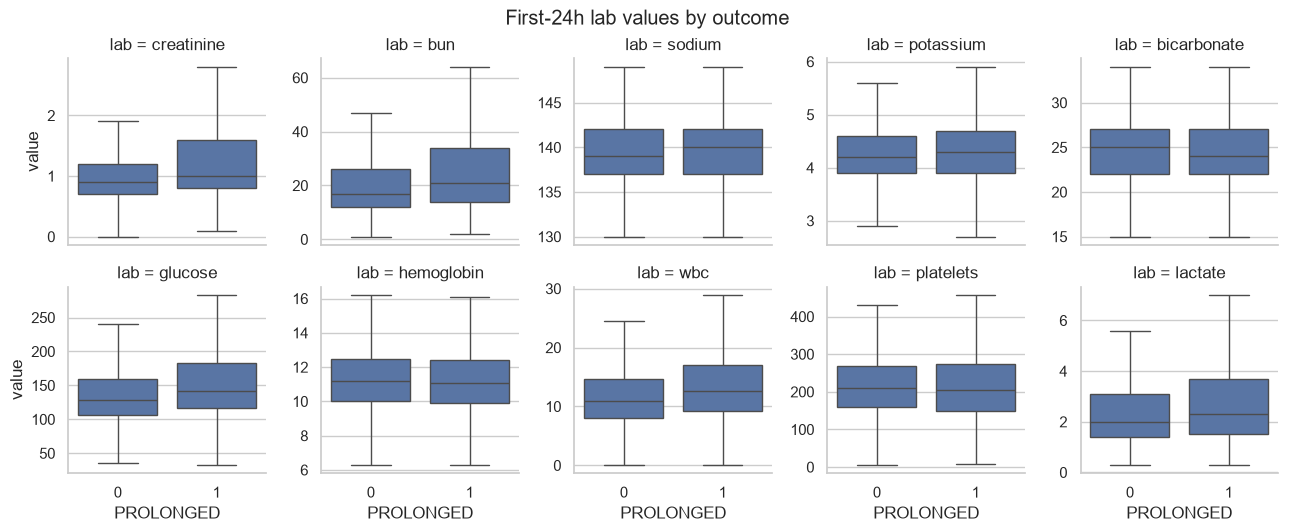

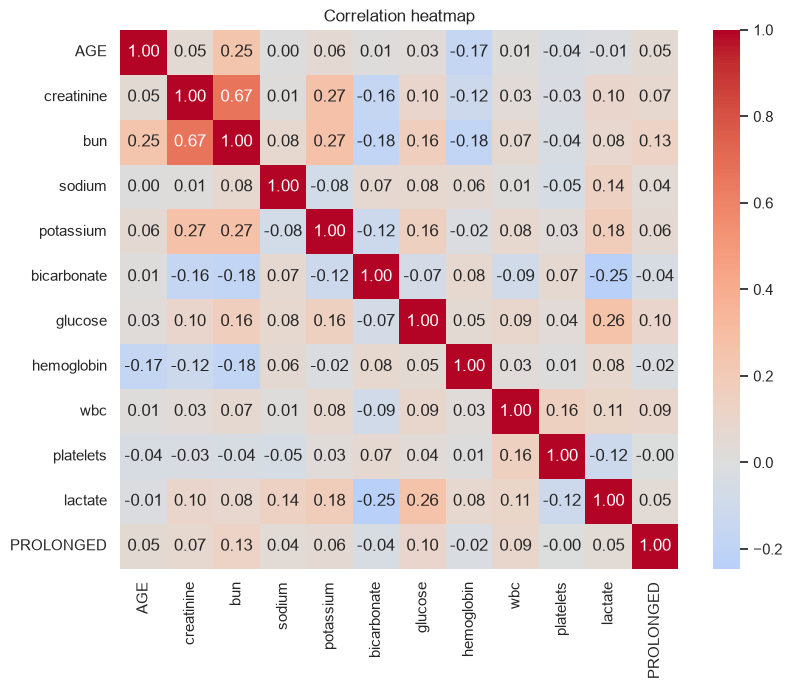

In [29]:
# ## Step 6. Explore the data (EDA)

plot_df = df[lab_cols + ["PROLONGED"]].melt(id_vars="PROLONGED",
                                            var_name="lab", value_name="value")
g = sns.catplot(data=plot_df, x="PROLONGED", y="value", col="lab",
                col_wrap=5, kind="box", sharey=False, height=2.6,
                showfliers=False)  # hide extreme outliers for readability
g.fig.suptitle("First-24h lab values by outcome", y=1.02)
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df[["AGE"] + lab_cols + ["PROLONGED"]].corr(),
            cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

In [30]:
# ## Step 7. Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (30828, 14)  Test: (7708, 14)


In [31]:
# ## Step 8. Build the models

logreg = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced",
                                 random_state=RANDOM_STATE)),
])

rf = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    # Random forests do not need scaling.
    ("model", RandomForestClassifier(n_estimators=300, max_depth=8,
                                     min_samples_leaf=20,
                                     class_weight="balanced",
                                     n_jobs=-1, random_state=RANDOM_STATE)),
])

logreg.fit(X_train, y_train)
rf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['AGE','MALE','ADMISSION_TYPE_EMERGENCY',...,'wbc','platelets','lactate']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object dat

Logistic Regression: AUROC = 0.644
Random Forest: AUROC = 0.703


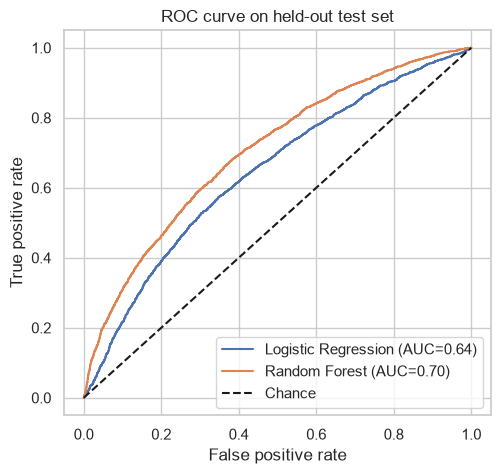

Best model: Random Forest
              precision    recall  f1-score   support

       Short       0.76      0.68      0.72      4979
   Prolonged       0.51      0.62      0.56      2729

    accuracy                           0.66      7708
   macro avg       0.64      0.65      0.64      7708
weighted avg       0.67      0.66      0.66      7708



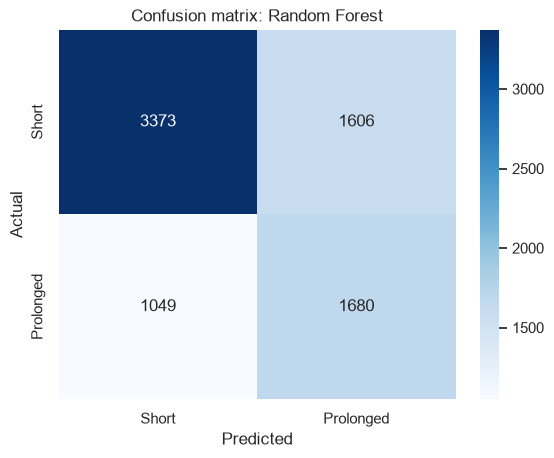

In [32]:
# ## Step 9. Evaluate

results = {}
for name, model in [("Logistic Regression", logreg), ("Random Forest", rf)]:
    proba = model.predict_proba(X_test)[:, 1]   # predicted probability of class 1
    results[name] = (model, proba)
    print(f"{name}: AUROC = {roc_auc_score(y_test, proba):.3f}")


plt.figure(figsize=(5.5, 5))
for name, (model, proba) in results.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve on held-out test set")
plt.legend()
plt.show()

best_name = max(results, key=lambda n: roc_auc_score(y_test, results[n][1]))
best_model = results[best_name][0]
pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, pred, target_names=["Short", "Prolonged"]))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Short", "Prolonged"], yticklabels=["Short", "Prolonged"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

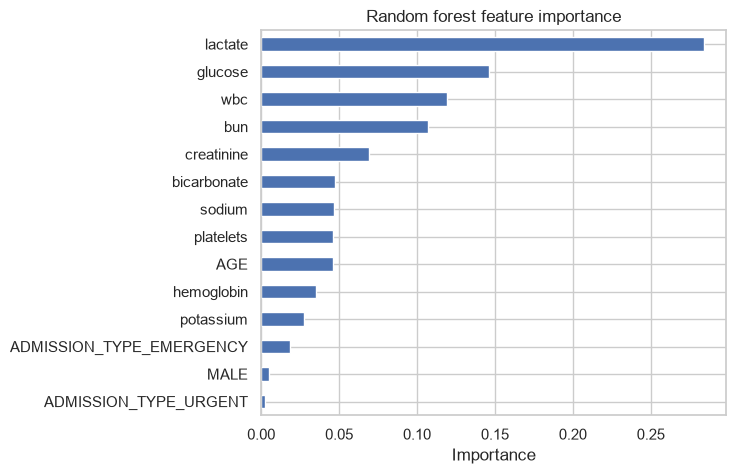

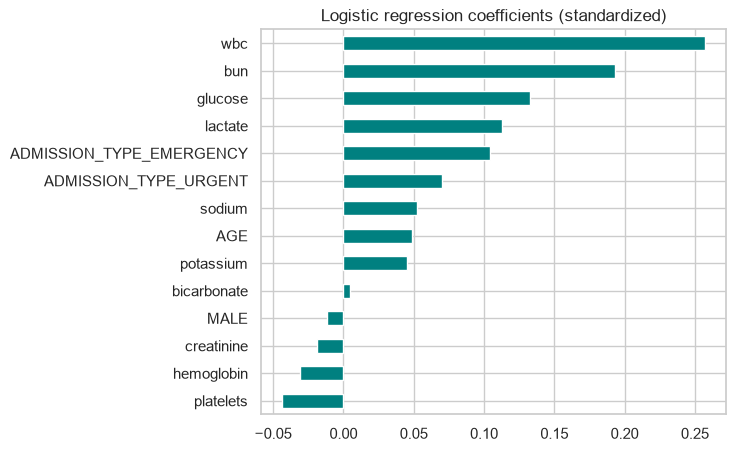

In [33]:
# ## Step 10. Interpret the model

importances = pd.Series(rf.named_steps["model"].feature_importances_,
                        index=FEATURES).sort_values()
importances.plot(kind="barh", figsize=(6, 5))
plt.title("Random forest feature importance")
plt.xlabel("Importance")
plt.show()

coefs = pd.Series(logreg.named_steps["model"].coef_[0],
                  index=FEATURES).sort_values()
coefs.plot(kind="barh", figsize=(6, 5), color="teal")
plt.title("Logistic regression coefficients (standardized)")
plt.show()